In [1]:
import pandas as pd 


# 读取 Feather 文件
data = pd.read_feather(rf'//project/model_share/share_1_new/factor_csy/fac20250613/fill_zero.fea')

print("✅ Feather 文件读取完成！")


✅ Feather 文件读取完成！


In [2]:
data[:10]

,date,Code,fac0001,fac0002,fac0003,fac0004,fac0005,fac0006,fac0007,fac0008,...,fac3035,fac3036,fac3037,fac3038,fac3039,fac3040,fac3041,fac3042,fac3043,fac3044
0,20210104,000001,0.103297,0.508136,-0.276862,-4.331658,0.261553,-5.413435,0.634146,-4.365740,...,0.009834,0.016627,0.014436,0.016538,0.014353,0.020904,0.020863,0.039058,0.032413,0.007140
1,20210104,000002,0.041108,0.692095,-0.148505,-3.625367,0.389545,3.513462,1.249417,-3.622822,...,0.004653,0.011976,0.012147,0.010844,0.011016,0.017384,0.016231,0.023557,0.018286,0.004495
2,20210104,000004,0.061697,0.900875,-0.046951,-1.091614,0.458014,0.000000,1.000000,-1.039020,...,-0.010993,-0.015484,-0.012007,-0.024155,-0.020684,-0.026982,-0.035714,-0.039314,-0.024251,-0.008712
3,20210104,000005,0.000000,0.932106,-0.026149,0.495133,0.558257,-2.639419,0.459459,0.573825,...,0.011329,-0.000568,0.002651,-0.000432,0.002787,-0.018660,-0.018512,-0.034847,-0.012931,0.009670
4,20210104,000006,0.032552,0.958341,-0.025876,-1.673883,0.331534,-3.014057,0.388889,-1.567781,...,-0.015754,0.013279,0.034034,0.013207,0.033960,0.036399,0.036317,0.056604,0.054037,-0.014980
5,20210104,000007,0.541024,0.000000,-0.994693,-1.826237,0.000000,-0.836105,0.813559,-1.848190,...,-0.147636,-0.154539,-0.153686,-0.171622,-0.170444,0.004918,-0.013638,0.208612,0.033461,-0.142704
6,20210104,000008,0.038402,0.811723,-0.095611,-2.963371,0.405330,-3.766941,0.432836,-2.908616,...,0.001008,-0.006728,-0.007232,-0.008223,-0.008727,-0.023417,-0.024910,-0.033701,-0.017139,0.000868
7,20210104,000009,0.182027,0.719200,-0.191238,-1.913540,0.228649,-3.785592,0.574803,-1.817809,...,-0.008438,-0.047177,-0.041414,-0.045641,-0.039880,-0.054035,-0.052467,-0.067854,-0.055058,-0.007033
8,20210104,000010,0.144204,0.639520,0.148647,1.195885,1.939908,-3.978168,0.546763,1.199352,...,-0.022014,-0.025434,-0.045672,-0.036448,-0.056679,-0.044965,-0.056138,-0.059566,-0.060314,-0.012184
9,20210104,000011,0.043398,0.919260,-0.058934,-3.149672,0.228621,-3.194936,0.450980,-3.128270,...,-0.016761,-0.010241,0.002024,-0.010429,0.001836,0.005072,0.004882,0.004071,0.001035,-0.014538


In [3]:
data = data.set_index("date").sort_index()
date_list = data.index.unique().tolist()
Code_list_data = data["Code"].unique().tolist()

total_stock_count = len(Code_list_data)
total_date_count = len(date_list)

In [4]:
stock_appearance_days = data.groupby("Code").size()  # 返回 Series：每只股票对应的行数（即出现的天数）
stocks_per_day = data.groupby("date")["Code"].nunique()  # 返回 Series：每个日期对应的不重复股票数

In [5]:
# stock_appearance_days[:10]
# stocks_per_day[-10:]
len(stock_appearance_days)

2903

In [6]:
stock_appearance_days_list = stock_appearance_days.to_list()
stocks_per_day_list = stocks_per_day.to_list()

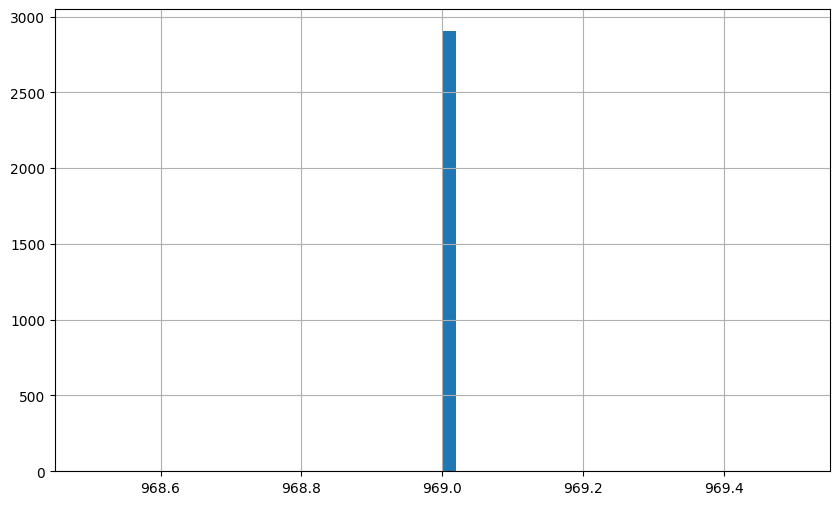

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.hist(stock_appearance_days_list, bins=50)
plt.grid(True)
plt.show()


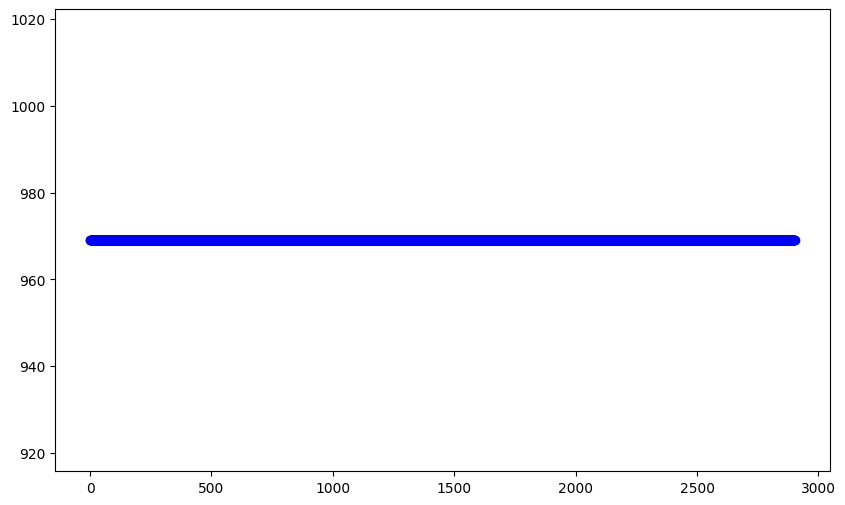

In [8]:

plt.figure(figsize=(10, 6))
plt.plot(stock_appearance_days_list, marker='o', linestyle='-', color='b')
plt.show()



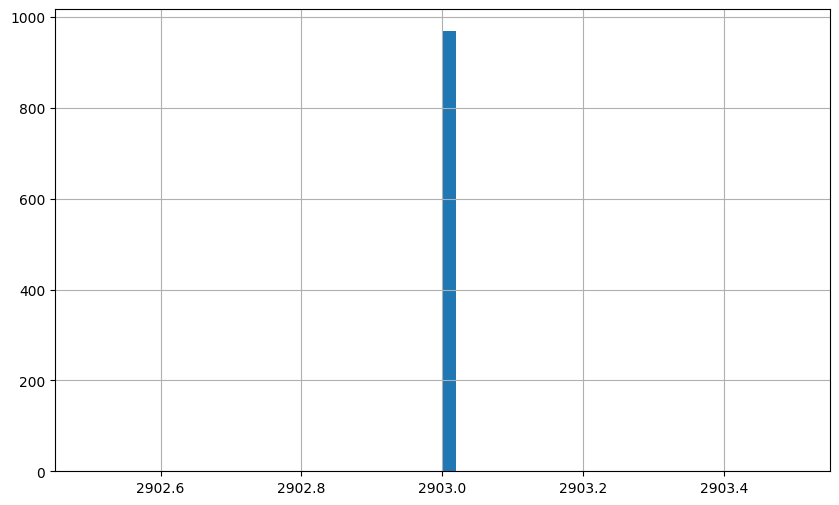

In [9]:

plt.figure(figsize=(10, 6))
plt.hist(stocks_per_day_list, bins=50)
plt.grid(True)
plt.show()


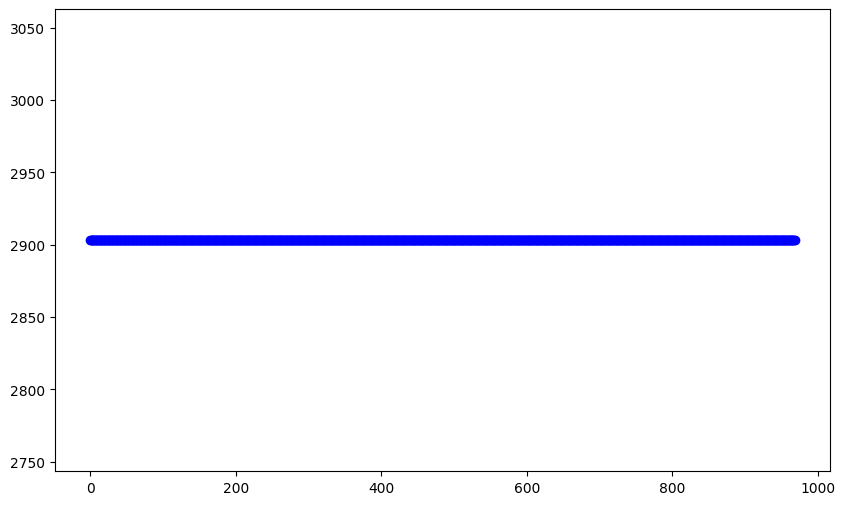

In [10]:

plt.figure(figsize=(10, 6))
plt.plot(stocks_per_day_list, marker='o', linestyle='-', color='b')
plt.show()

In [11]:
good_code_index = stock_appearance_days[stock_appearance_days > 968].index.tolist()

In [12]:
good_data = data[data["Code"].isin(good_code_index)]

In [13]:
good_data[3600:3630]

,Code,fac0001,fac0002,fac0003,fac0004,fac0005,fac0006,fac0007,fac0008,fac0009,...,fac3035,fac3036,fac3037,fac3038,fac3039,fac3040,fac3041,fac3042,fac3043,fac3044
date,,,,,,,,,,,,,,,,,,,,,
20210105,002316,0.088850,0.761938,-0.052074,1.960365,0.665688,2.063582,2.200000,1.990526,0.731903,...,0.084222,0.092857,0.063500,0.096573,0.067217,-0.052871,-0.049118,-0.154336,-0.036358,0.078989
20210105,002317,0.334049,0.749675,0.548326,4.968675,9.384935,16.157850,4.081218,4.916831,12.015764,...,-0.046046,-0.033160,-0.032272,-0.033825,-0.032931,-0.029251,-0.029938,0.003077,0.001063,-0.032918
20210105,002318,0.312770,0.715730,-0.001270,1.137746,0.885709,0.374731,1.049180,1.167643,0.980819,...,0.069396,-0.003226,-0.002706,-0.016580,-0.016046,-0.080284,-0.093860,-0.134816,-0.054592,0.060611
20210105,002320,0.123402,0.679703,-0.243500,-2.976212,0.159498,-3.114532,0.508772,-2.904866,0.176802,...,-0.007954,-0.007105,-0.007785,-0.007516,-0.008205,0.000686,0.000259,0.008565,-0.000182,-0.007246
20210105,002321,0.445543,0.553145,-0.153301,-0.834246,0.450056,-0.461996,0.948276,-0.795064,0.508159,...,0.009925,-0.142094,-0.084608,-0.266963,-0.213293,-0.065609,-0.193876,-0.136175,-0.156605,0.008752
20210105,002322,0.011029,0.853315,-0.107999,-1.850514,0.216028,-3.425099,0.312500,-1.822393,0.234692,...,0.011114,-1.461191,-1.454266,-1.457824,-1.450993,-1.491521,-1.487583,-1.522736,-1.478232,0.009104
20210105,002324,0.059521,0.755193,-0.124389,0.131684,0.374344,-3.206961,0.595960,0.218497,0.423144,...,0.099484,0.069786,0.067380,0.075741,0.073328,-0.059578,-0.053623,-0.210821,-0.077368,0.090070
20210105,002325,0.024288,0.968784,-0.016538,0.217450,0.427113,-0.173937,0.937500,0.250246,0.461078,...,-0.028951,0.017518,0.017824,-0.008720,-0.008416,0.039777,0.009820,0.035735,0.013757,-0.024880
20210105,002326,0.132057,0.634033,-0.271930,-3.081828,0.155086,-3.217704,0.680000,-3.048865,0.174793,...,0.124687,0.086191,0.089406,0.087245,0.090835,-0.001330,0.000659,-0.076793,0.017748,0.112621


In [14]:
# 1. 获取所有唯一日期和股票代码
all_dates = good_data.index.unique()          # 因为你的 data 已设定 "date" 为 index
all_codes = good_data["Code"].unique()

# 2. 创建 MultiIndex：所有日期 × 所有股票
full_index = pd.MultiIndex.from_product([all_dates, all_codes], names=["date", "Code"])

# 3. 将原数据以 MultiIndex 形式重建，并 reindex 到完整索引上
good_data_full = good_data.reset_index().set_index(["date", "Code"]).reindex(full_index)


In [15]:
# 1. 重置索引，把 "date" 和 "Code" 变回普通列
good_data_full_reset = good_data_full.reset_index()

# 2. 保存为 feather 格式（.fea 只是简称，实际上是 .feather 文件）
# good_data_full_reset.to_feather("/project/model_share/share_1_new/factor_csy/fac20250625_v2/fac20250625_v2.fea")